# UrbanSound8K - Environmental Sound Classification
End-to-end ML pipeline: acquisition → preprocessing → model → evaluation → prediction → retraining.

**Before running:** set `DATASET` below to your downloaded `UrbanSound8K` folder.

In [1]:
import sys, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '..')                      # so `src` is importable from /notebook
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import librosa, librosa.display
from src.config import *
from src import preprocessing as pp, model as ml, prediction, visualization
from src.data_acquisition import build_dataset

DATASET = Path('C:/Users/HP/Documents/UrbanSound8K')

In [4]:
import inspect
print('_augment' in inspect.getsource(ml))

True


## 1. Data acquisition
Folds 1-9 → `data/train`, fold 10 → `data/test`. We keep the official fold boundaries because clips cut from the same recording share a fold; reshuffling would leak near-duplicates into the test set.

In [ ]:
meta = pd.read_csv(DATASET / 'metadata' / 'UrbanSound8K.csv')
build_dataset(DATASET)
meta.head()

Copied 0 files. Train: 7895  Test: 837


,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.0,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.5,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.5,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.0,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.5,72.500000,1,5,2,children_playing


## 2. Exploratory analysis & visualisations (the 'story' of the data)

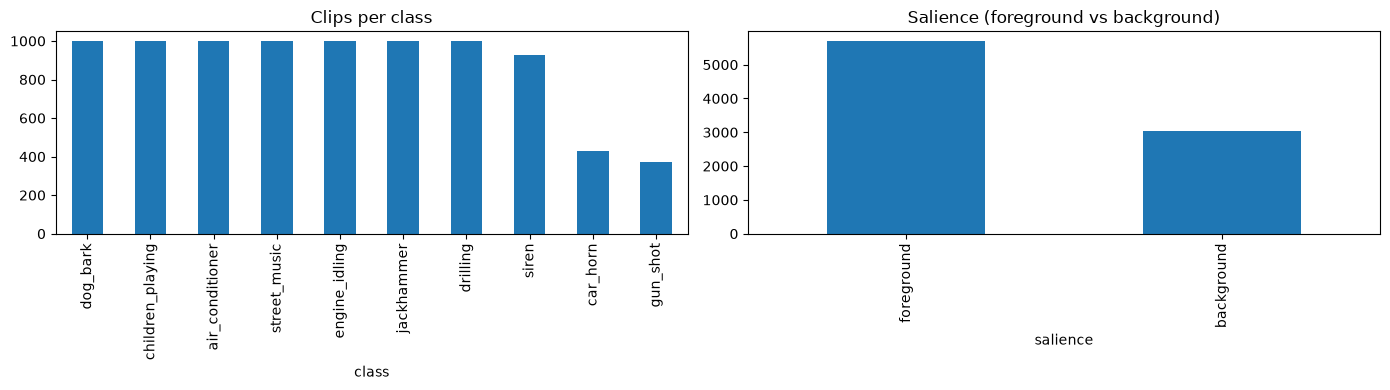

class
air_conditioner     3.99
car_horn            2.46
children_playing    3.96
dog_bark            3.15
drilling            3.55
engine_idling       3.94
gun_shot            1.65
jackhammer          3.61
siren               3.91
street_music        4.00
Name: mean clip length (s), dtype: float64

In [6]:
# Feature 1: class balance
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
meta['class'].value_counts().plot.bar(ax=ax[0], title='Clips per class')
meta['salience'].map({1: 'foreground', 2: 'background'}).value_counts().plot.bar(ax=ax[1], title='Salience (foreground vs background)')
plt.tight_layout(); plt.show()
meta.groupby('class').apply(lambda d: (d['end'] - d['start']).mean()).round(2).rename('mean clip length (s)')

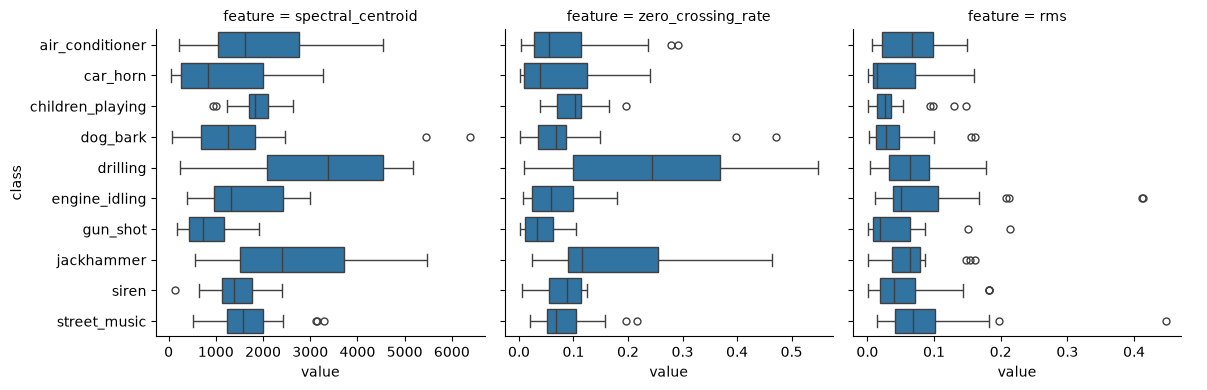

In [7]:
# Feature 2: spectral centroid / zero-crossing rate / RMS per class (sampled)
viz = visualization.compute_viz(sample_per_class=30, force=True)
feat_df = pd.DataFrame([{'class': c, 'feature': k, 'value': v}
                        for c, d in viz['features'].items() for k, vals in d.items() for v in vals])
g = sns.catplot(data=feat_df, x='value', y='class', col='feature', kind='box', sharex=False, height=4, aspect=1)
plt.show()

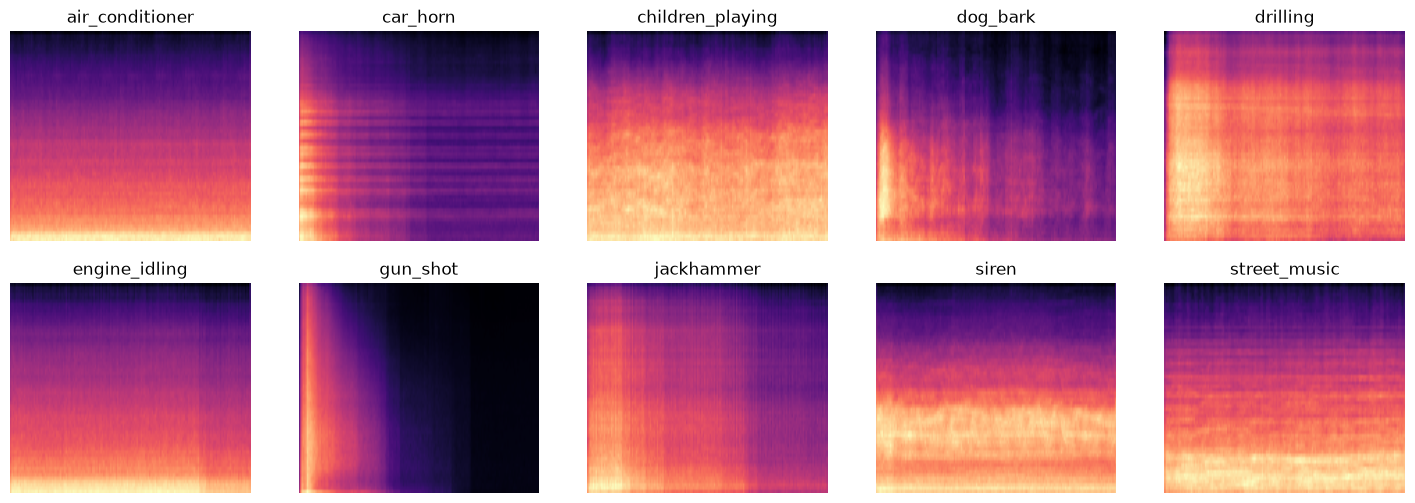

In [8]:
# Feature 3: mean log-mel spectrogram per class
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, (c, S) in zip(axes.ravel(), viz['mean_spectrograms'].items()):
    ax.imshow(np.array(S), origin='lower', aspect='auto', cmap='magma'); ax.set_title(c); ax.axis('off')
plt.show()

### Interpretation
1. **Class balance:** car_horn and gun_shot have far fewer clips than the other classes (33 and 32 test clips against about 100), and they're also the shortest (gun_shot averages 1.65 s, car_horn 2.46 s, against about 4 s for most classes). Accuracy alone could hide failures on these small classes, so we use class weights and report macro-averaged metrics. The result is that gun_shot reaches recall 1.00 (32 of 32) and car_horn 0.94 (31 of 33), so the imbalance is handled. Short clips are zero-padded to 4 s, and the silence after the burst makes gun shots especially easy to recognise.

2. **Spectral features:** Drilling is the brightest and noisiest class, with a median centroid of roughly 3,400 Hz and the highest zero-crossing rate and widest spread. Jackhammer comes second (about 2,400 Hz), and their ranges overlap heavily, which is why the model still mistakes 11 drilling clips for jackhammer. Gun_shot has the lowest centroid (about 700 Hz) and low energy, which makes it easy to separate. Air conditioner, engine idling, siren and street music all have centroids of about 1,200 to 1,600 Hz, so simple features cannot separate them, and the CNN has to use finer spectral detail.

3. **Mean spectrograms:** Air conditioner and engine idling look almost identical: a smooth texture with energy at low frequencies. This is the largest remaining confusion: 21 engine_idling clips are labelled air_conditioner, which also drags air_conditioner's precision down to 0.64. Drilling and jackhammer are both bright and broadband, differing mainly in the repeated vertical impact stripes of the jackhammer. Gun_shot is a bright burst at the start that decays into silence, car_horn shows clear horizontal harmonic lines, and dog_bark shows short vertical bursts that fade over time. Siren has steady bright bands at low and mid frequencies, similar to the machine noises, which explains the errors below.

## 3. Preprocessing
Every clip is resampled to 22.05 kHz mono, padded/trimmed to 4 s, converted to a 64-band log-mel spectrogram (dB) and standardised per clip → input shape `(64, 173, 1)`.

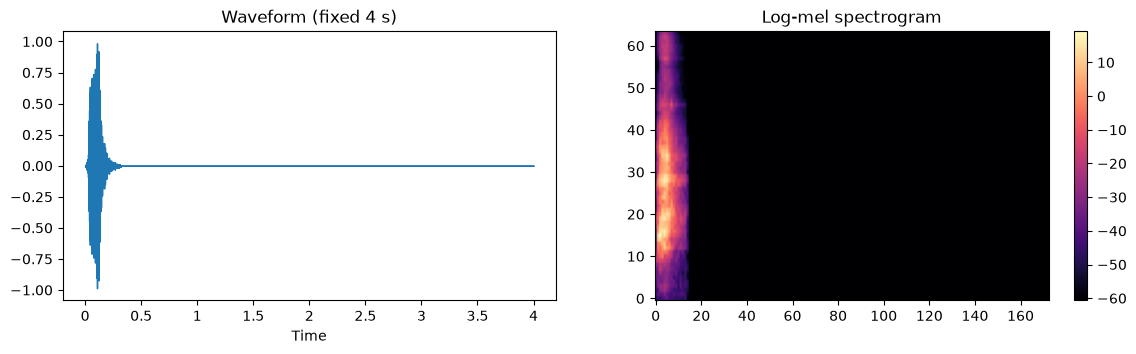

In [9]:
sample = next(Path(TRAIN_DIR / 'dog_bark').glob('*.wav'))
y = pp.load_audio(str(sample)); S = pp.mel_db(y, normalize=False)[..., 0]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
librosa.display.waveshow(y, sr=SR, ax=ax[0]); ax[0].set_title('Waveform (fixed 4 s)')
im = ax[1].imshow(S, origin='lower', aspect='auto', cmap='magma'); ax[1].set_title('Log-mel spectrogram'); plt.colorbar(im, ax=ax[1])
plt.show()

In [2]:
X, y, groups, _ = pp.load_dataset([TRAIN_DIR])
Xt, yt, _, _ = pp.load_dataset([TEST_DIR])
print('train', X.shape, 'test', Xt.shape)

  processed 1000/7895
  processed 2000/7895
  processed 3000/7895
  processed 4000/7895
  processed 5000/7895
  processed 6000/7895
  processed 7000/7895
train (7895, 64, 173, 1) test (837, 64, 173, 1)


## 4. Model creation
Baseline CNN vs optimised CNN (BatchNorm, Dropout, L2, global average pooling, class weights, early stopping, LR-on-plateau). The train/validation split is grouped by source recording to avoid leakage.

In [11]:
base = ml.build_baseline()
h_base = ml.fit_model(base, X, y, groups, epochs=20)
opt = ml.build_cnn(); opt.summary()
h_opt = ml.fit_model(opt, X, y, groups, epochs=40)

Epoch 1/20
212/212 - 32s - 152ms/step - accuracy: 0.3960 - loss: 1.6808 - val_accuracy: 0.4964 - val_loss: 1.4609 - learning_rate: 0.0010
Epoch 2/20
212/212 - 7s - 33ms/step - accuracy: 0.5919 - loss: 1.1515 - val_accuracy: 0.5473 - val_loss: 1.2081 - learning_rate: 0.0010
Epoch 3/20
212/212 - 8s - 40ms/step - accuracy: 0.6509 - loss: 0.9683 - val_accuracy: 0.5661 - val_loss: 1.2180 - learning_rate: 0.0010
Epoch 4/20
212/212 - 8s - 40ms/step - accuracy: 0.6925 - loss: 0.8662 - val_accuracy: 0.6000 - val_loss: 1.1638 - learning_rate: 0.0010
Epoch 5/20
212/212 - 8s - 39ms/step - accuracy: 0.7247 - loss: 0.7944 - val_accuracy: 0.6313 - val_loss: 1.0655 - learning_rate: 0.0010
Epoch 6/20
212/212 - 18s - 85ms/step - accuracy: 0.7511 - loss: 0.7099 - val_accuracy: 0.6027 - val_loss: 1.1527 - learning_rate: 0.0010
Epoch 7/20
212/212 - 7s - 31ms/step - accuracy: 0.7712 - loss: 0.6619 - val_accuracy: 0.6143 - val_loss: 1.1392 - learning_rate: 0.0010
Epoch 8/20
212/212 - 32s - 150ms/step - accur

Model: "urbansound_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 173, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 173, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 86, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 86, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 86, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 86, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 43, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 43, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 21, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 21, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,370 (435.04 KB)

 Trainable params: 110,922 (433.29 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/40
212/212 - 203s - 956ms/step - accuracy: 0.3746 - loss: 1.7248 - val_accuracy: 0.0848 - val_loss: 3.6673 - learning_rate: 0.0010
Epoch 2/40
212/212 - 237s - 1s/step - accuracy: 0.5655 - loss: 1.2301 - val_accuracy: 0.2286 - val_loss: 3.8093 - learning_rate: 0.0010
Epoch 3/40
212/212 - 277s - 1s/step - accuracy: 0.6483 - loss: 1.0131 - val_accuracy: 0.5098 - val_loss: 1.7708 - learning_rate: 0.0010
Epoch 4/40
212/212 - 267s - 1s/step - accuracy: 0.7095 - loss: 0.8743 - val_accuracy: 0.5875 - val_loss: 1.2461 - learning_rate: 0.0010
Epoch 5/40
212/212 - 222s - 1s/step - accuracy: 0.7461 - loss: 0.7757 - val_accuracy: 0.6196 - val_loss: 1.3252 - learning_rate: 0.0010
Epoch 6/40
212/212 - 198s - 934ms/step - accuracy: 0.7789 - loss: 0.6941 - val_accuracy: 0.6170 - val_loss: 1.4827 - learning_rate: 0.0010
Epoch 7/40
212/212 - 195s - 922ms/step - accuracy: 0.8007 - loss: 0.6266 - val_accuracy: 0.6402 - val_loss: 1.3125 - learning_rate: 0.0010
Epoch 8/40
212/212 - 98s - 462ms/step -

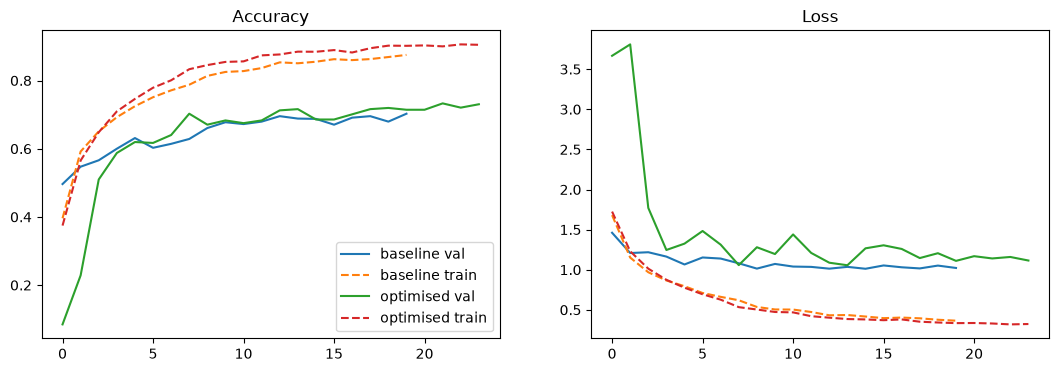

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, h in [('baseline', h_base), ('optimised', h_opt)]:
    ax[0].plot(h['val_accuracy'], label=f'{name} val'); ax[0].plot(h['accuracy'], '--', label=f'{name} train')
    ax[1].plot(h['val_loss'], label=f'{name} val'); ax[1].plot(h['loss'], '--', label=f'{name} train')
ax[0].set_title('Accuracy'); ax[1].set_title('Loss'); ax[0].legend(); plt.show()

## 5. Model testing - all metrics on the held-out fold 10

In [13]:
m_base, m_opt = ml.evaluate(base, Xt, yt), ml.evaluate(opt, Xt, yt)
pd.DataFrame({'baseline': m_base, 'optimised': m_opt}).loc[['accuracy', 'loss', 'precision_macro', 'recall_macro', 'f1_macro']].round(3)

,baseline,optimised
accuracy,0.729988,0.774194
loss,1.150881,0.814407
precision_macro,0.764061,0.800338
recall_macro,0.751641,0.796589
f1_macro,0.751745,0.792561


                  precision  recall  f1-score  support
air_conditioner       0.617   0.790     0.693  100.000
car_horn              0.886   0.939     0.912   33.000
children_playing      0.737   0.700     0.718  100.000
dog_bark              0.727   0.720     0.724  100.000
drilling              0.732   0.820     0.774  100.000
engine_idling         0.825   0.710     0.763   93.000
gun_shot              0.941   1.000     0.970   32.000
jackhammer            0.838   0.969     0.899   96.000
siren                 0.811   0.518     0.632   83.000
street_music          0.889   0.800     0.842  100.000
accuracy              0.774   0.774     0.774    0.774
macro avg             0.800   0.797     0.793  837.000
weighted avg          0.781   0.774     0.772  837.000


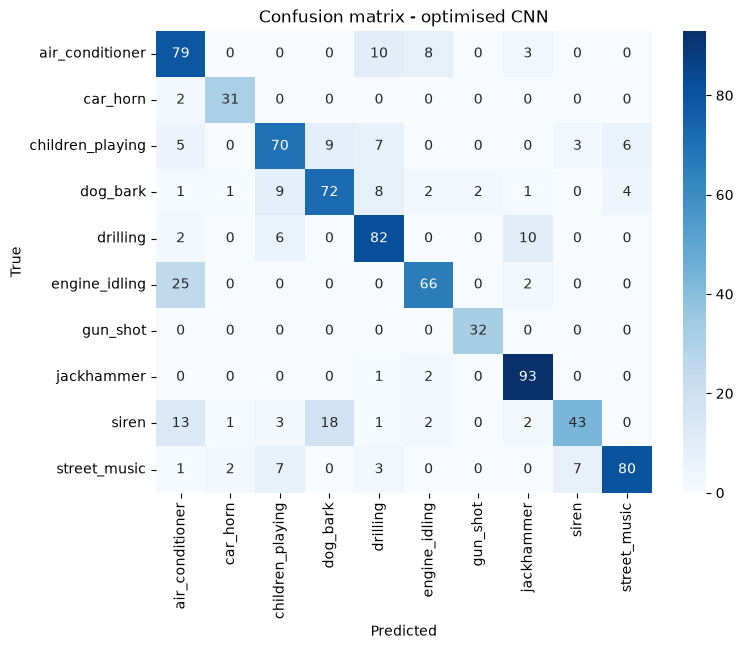

In [14]:
print(pd.DataFrame(m_opt['report']).T.round(3))
plt.figure(figsize=(8, 6))
sns.heatmap(m_opt['confusion_matrix'], annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix - optimised CNN'); plt.show()

**Production model results (v1, test fold 10)**: accuracy 0.784, macro-precision 0.804, macro-recall 0.804, macro-F1 0.795.

**Strongest classes**: gun_shot (F1 0.91), car_horn (0.90), jackhammer (0.87) and street_music (0.85). Jackhammer's recall of 0.96 is high partly because it absorbs some drilling clips.

**Weakest class**: siren (recall 0.48, F1 0.61). Of 83 siren clips, 15 were predicted as air_conditioner, 14 as dog_bark and 9 as children_playing. Siren clips often have background noise or are recorded far away, so their energy resembles steady machine noise.

**Engine idling** has high precision (0.92) but recall of 0.71, because 21 clips go to air_conditioner. 

**Air conditioner** shows the opposite: high recall (0.85) but low precision (0.64).

**Children playing and dog bark** are confused in both directions (10 and 7 clips). Both are short, irregular, mid-frequency sounds.

## 6. Save the production model
`train_model` trains the optimised CNN, evaluates it, writes `models/urbansound_cnn.h5` and records metrics in `models/registry.json`.

In [15]:
entry = ml.train_model(epochs=40)
print('model version', entry['version'], '| accuracy', round(entry['metrics']['accuracy'], 3), '| macro-F1', round(entry['metrics']['f1_macro'], 3))

  processed 1000/7895
  processed 2000/7895
  processed 3000/7895
  processed 4000/7895
  processed 5000/7895
  processed 6000/7895
  processed 7000/7895
Epoch 1/40
212/212 - 66s - 310ms/step - accuracy: 0.3672 - loss: 1.7269 - val_accuracy: 0.1857 - val_loss: 3.8187 - learning_rate: 0.0010
Epoch 2/40
212/212 - 62s - 293ms/step - accuracy: 0.5601 - loss: 1.2336 - val_accuracy: 0.2018 - val_loss: 3.6987 - learning_rate: 0.0010
Epoch 3/40
212/212 - 64s - 303ms/step - accuracy: 0.6474 - loss: 1.0154 - val_accuracy: 0.4866 - val_loss: 1.5554 - learning_rate: 0.0010
Epoch 4/40
212/212 - 75s - 352ms/step - accuracy: 0.7117 - loss: 0.8531 - val_accuracy: 0.3821 - val_loss: 2.4439 - learning_rate: 0.0010
Epoch 5/40
212/212 - 73s - 345ms/step - accuracy: 0.7457 - loss: 0.7805 - val_accuracy: 0.6161 - val_loss: 1.1765 - learning_rate: 0.0010
Epoch 6/40
212/212 - 126s - 592ms/step - accuracy: 0.7746 - loss: 0.6905 - val_accuracy: 0.6143 - val_loss: 1.4010 - learning_rate: 0.0010
Epoch 7/40
212/21

model version 1 | accuracy 0.784 | macro-F1 0.795


{'accuracy': 0.784, 'precision_macro': 0.804, 'recall_macro': 0.804, 'f1_macro': 0.795}
                  precision  recall  f1-score  support
air_conditioner       0.644   0.850     0.733  100.000
car_horn              0.861   0.939     0.899   33.000
children_playing      0.724   0.760     0.741  100.000
dog_bark              0.758   0.750     0.754  100.000
drilling              0.775   0.790     0.782  100.000
engine_idling         0.917   0.710     0.800   93.000
gun_shot              0.842   1.000     0.914   32.000
jackhammer            0.793   0.958     0.868   96.000
siren                 0.816   0.482     0.606   83.000
street_music          0.909   0.800     0.851  100.000
accuracy              0.784   0.784     0.784    0.784
macro avg             0.804   0.804     0.795  837.000
weighted avg          0.795   0.784     0.780  837.000


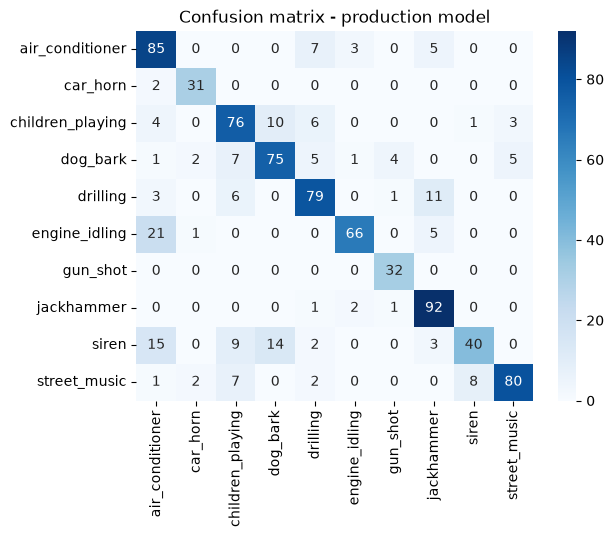

In [3]:
import tensorflow as tf
prod = tf.keras.models.load_model(MODEL_PATH, compile=False)
m_prod = ml.evaluate(prod, Xt, yt)
print({k: round(m_prod[k], 3) for k in ('accuracy','precision_macro','recall_macro','f1_macro')})
print(pd.DataFrame(m_prod['report']).T.round(3))
sns.heatmap(m_prod['confusion_matrix'], annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Confusion matrix - production model'); plt.show()

## 7. Prediction function

true: siren | predicted: siren (99.4%)


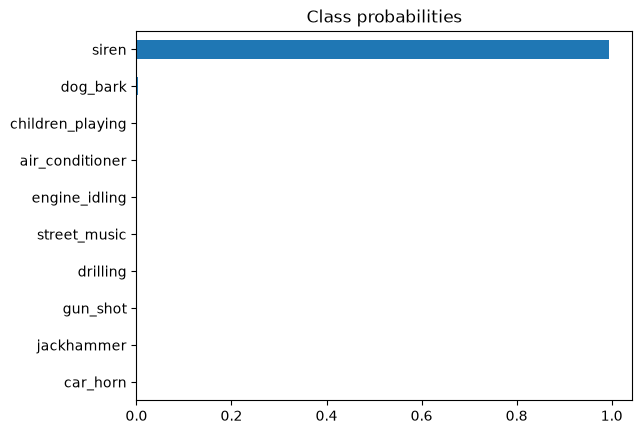

In [16]:
test_file = next(Path(TEST_DIR / 'siren').glob('*.wav'))
res = prediction.predict(str(test_file))
print('true: siren | predicted:', res['class'], f"({res['confidence']:.1%})")
pd.Series(res['probabilities']).sort_values().plot.barh(title='Class probabilities'); plt.show()